# Figure 7e. Colocalization of AD, *INO80E* *cis*-eQTL and DLPFC *ABCA1* *trans*-eQTL at chr16p11.2

Stacked locus plots of the chr16 INO80E region (~29.7-30.2 Mb): AD GWAS, excitatory-neuron and oligodendrocyte *INO80E* *cis*-eQTL, and DLPFC *ABCA1* *trans*-eQTL. The y-axis is -log10 marginal p. The AD-focal ColocBoost colocalization set CoS15 (green) is shared by all four traits. The gene track shows only the genes labelled in the published panel; *INO80E* is highlighted.

All 32 CoS15 variants from the ColocBoost result are shown. The published panel omits two of them (chr16:29971163:G:A and chr16:29977028:G:A; AD -log10 p ≈ 4.4).

Input: `data/Figure_7e_INO80E_locus.rds`

In [1]:
library(ggplot2)
library(patchwork)
dat <- readRDS("data/Figure_7e_INO80E_locus.rds")
loc <- dat$locus
head(loc)
## variants per trait and number in the colocalization set (CoS)
table(loc$trait, ifelse(is.na(loc$cos), "background", loc$cos))
dat$genes[dat$genes$in_figure, ]

,trait,variant,position,neg_log10_p,cos,cos_colour
,<fct>,<chr>,<dbl>,<dbl>,<chr>,<chr>
1,Alzheimer's disease GWAS,chr16:29718925:G:A,29718925,0.09067632,NA,NA
2,Alzheimer's disease GWAS,chr16:29719305:A:G,29719305,0.11041549,NA,NA
3,Alzheimer's disease GWAS,chr16:29721639:G:A,29721639,0.03397667,NA,NA
4,Alzheimer's disease GWAS,chr16:29722036:T:C,29722036,0.04343702,NA,NA
5,Alzheimer's disease GWAS,chr16:29722391:C:T,29722391,0.08979289,NA,NA
6,Alzheimer's disease GWAS,chr16:29722993:G:A,29722993,0.12204231,NA,NA


                                  
                                   CoS15 background
  Alzheimer's disease GWAS            32        329
  Exc. neuron INO80E cis-eQTL         32        329
  Oligodendrocytes INO80E cis-eQTL    32        329
  DLPFC ABCA1 trans-eQTL              32        329

,gene,chrom,start,end,strand,in_figure,highlight
,<chr>,<chr>,<int>,<int>,<chr>,<lgl>,<lgl>
9,MVP,chr16,29820394,29848039,+,TRUE,FALSE
10,CDIPT,chr16,29858357,29863414,-,TRUE,FALSE
11,SEZ6L2,chr16,29871159,29899547,-,TRUE,FALSE
12,ASPHD1,chr16,29900375,29919864,+,TRUE,FALSE
13,KCTD13,chr16,29905012,29926236,-,TRUE,FALSE
14,TMEM219,chr16,29940885,29973050,+,TRUE,FALSE
15,TAOK2,chr16,29973868,29992261,+,TRUE,FALSE
17,INO80E,chr16,29995715,30005793,+,TRUE,TRUE
18,DOC2A,chr16,30005514,30023270,-,TRUE,FALSE


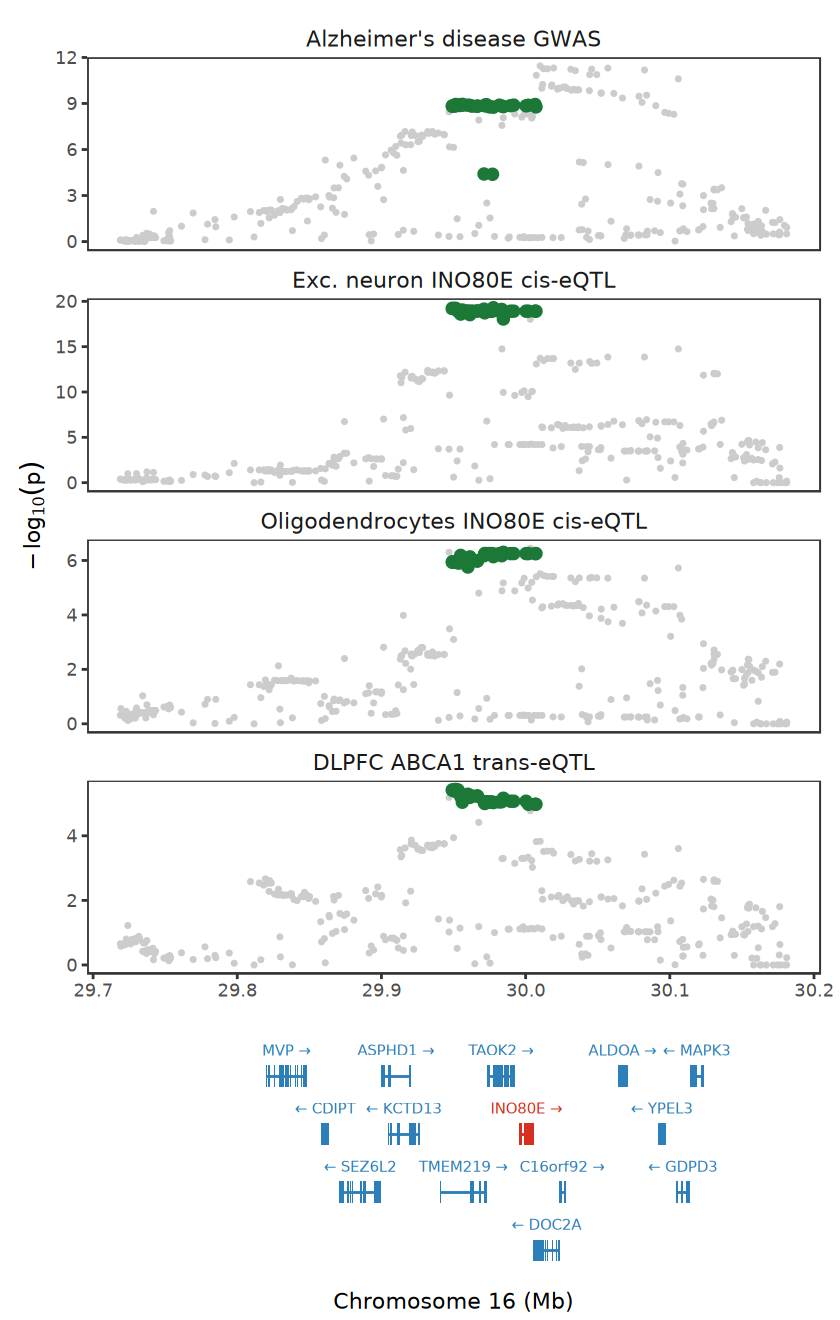

In [2]:

locus_plot <- function(dat, chrom_label, track_height = 1, annot = NULL) {
  loc  <- dat$locus
  xlim <- range(loc$position) / 1e6
  bg <- loc[is.na(loc$cos), ]
  fg <- loc[!is.na(loc$cos), ]
  cos_pal <- unique(fg[, c("cos", "cos_colour")])
  cos_pal <- setNames(cos_pal$cos_colour, cos_pal$cos)

  p_loc <- ggplot() +
    geom_point(data = bg, aes(position / 1e6, neg_log10_p), colour = "grey80", size = 0.8) +
    geom_point(data = fg, aes(position / 1e6, neg_log10_p, colour = cos), size = 2.6) +
    scale_colour_manual(values = cos_pal, guide = "none") +
    facet_wrap(~trait, ncol = 1, scales = "free_y") +
    coord_cartesian(xlim = xlim) +
    labs(x = NULL, y = expression(-log[10](p))) +
    theme_bw(base_size = 13) +
    theme(panel.grid = element_blank(), strip.background = element_blank(),
          strip.text = element_text(size = 13))
  if (!is.null(annot)) p_loc <- p_loc + annot

  ## gene track: only genes drawn in the published panel, packed into rows
  genes <- dat$genes[dat$genes$in_figure, ]
  genes <- genes[order(genes$start), ]
  pad <- diff(xlim) * 1e6 * 0.08
  row_end <- numeric(0); genes$row <- NA
  for (i in seq_len(nrow(genes))) {
    r <- which(row_end < genes$start[i] - pad)[1]
    if (is.na(r)) r <- length(row_end) + 1
    row_end[r] <- genes$end[i]; genes$row[i] <- r
  }
  genes$label <- ifelse(genes$strand == "+", paste0(genes$gene, " →"), paste0("← ", genes$gene))
  exons <- dat$exons[dat$exons$gene %in% genes$gene, ]
  exons$row <- genes$row[match(exons$gene, genes$gene)]
  exons$highlight <- genes$highlight[match(exons$gene, genes$gene)]
  hl <- c(`TRUE` = "#D7301F", `FALSE` = "#2C7FB8")

  p_gene <- ggplot(genes) +
    geom_segment(aes(x = start / 1e6, xend = end / 1e6, y = -row, yend = -row, colour = highlight),
                 linewidth = 0.6) +
    geom_rect(data = exons, aes(xmin = start / 1e6, xmax = end / 1e6, ymin = -row - 0.18,
                                ymax = -row + 0.18, fill = highlight)) +
    geom_text(aes(x = (start + end) / 2e6, y = -row + 0.45, label = label, colour = highlight), size = 3) +
    scale_colour_manual(values = hl, guide = "none") +
    scale_fill_manual(values = hl, guide = "none") +
    scale_y_continuous(expand = expansion(add = c(0.4, 0.7))) +
    coord_cartesian(xlim = xlim) +
    labs(x = chrom_label) +
    theme_void(base_size = 13) +
    theme(axis.title.x = element_text(margin = margin(t = 4)))

  p_loc / p_gene + plot_layout(heights = c(nlevels(loc$trait), track_height))
}

p <- locus_plot(dat, "Chromosome 16 (Mb)", track_height = 1.2)
options(repr.plot.width = 7, repr.plot.height = 11)
p